In [10]:

import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/fedesoriano/cifar100/meta
/kaggle/input/datasets/fedesoriano/cifar100/file.txt
/kaggle/input/datasets/fedesoriano/cifar100/test
/kaggle/input/datasets/fedesoriano/cifar100/train


Train: (50000, 32, 32, 3)
Test: (10000, 32, 32, 3)
Number of classes: 100


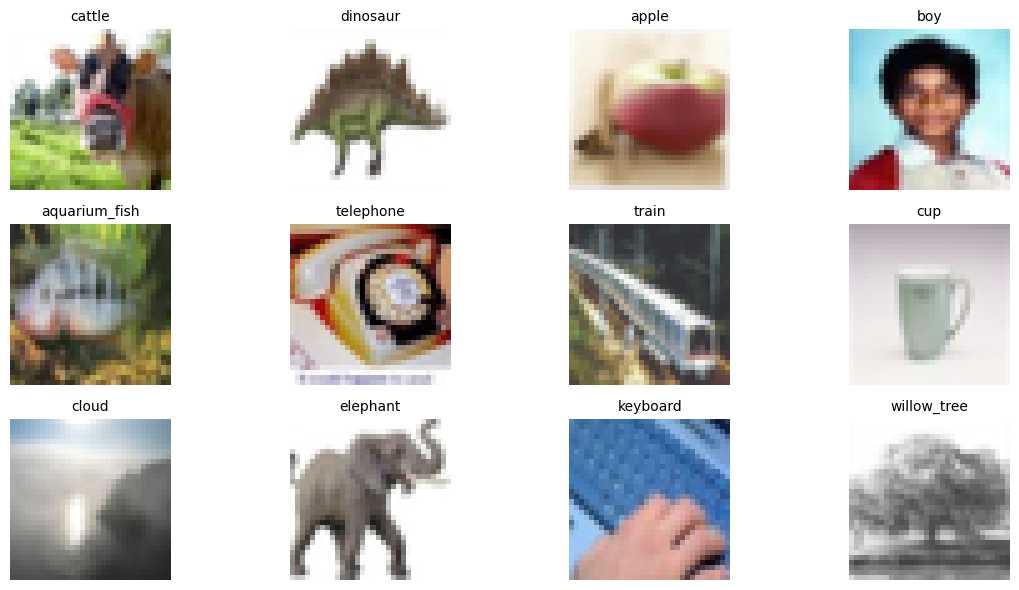

In [11]:

import pickle
import numpy as np
import matplotlib.pyplot as plt

# Dataset path
DATA_DIR = "/kaggle/input/datasets/fedesoriano/cifar100"

def load_cifar_file(filename):
    with open(f"{DATA_DIR}/{filename}", "rb") as f:
        return pickle.load(f, encoding="bytes")

# Load train and test
train_data = load_cifar_file("train")
test_data = load_cifar_file("test")
meta_data = load_cifar_file("meta")

# Convert to images 32x32x3
x_train = train_data[b"data"].reshape(
    -1, 3, 32, 32
).transpose(0, 2, 3, 1)

y_train = np.array(train_data[b"fine_labels"])

x_test = test_data[b"data"].reshape(
    -1, 3, 32, 32
).transpose(0, 2, 3, 1)

y_test = np.array(test_data[b"fine_labels"])

class_names = [
    name.decode("utf-8")
    for name in meta_data[b"fine_label_names"]
]

print("Train:", x_train.shape)
print("Test:", x_test.shape)
print("Number of classes:", len(class_names))

# Visualize sample images
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]], fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [12]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.random.set_seed(42)

# Split train and validation: 45,000 / 5,000
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train))

train_idx = indices[:45000]
val_idx = indices[45000:]

X_train = x_train[train_idx].astype("float32") / 255.0
Y_train = y_train[train_idx]

X_val = x_train[val_idx].astype("float32") / 255.0
Y_val = y_train[val_idx]

X_test = x_test.astype("float32") / 255.0
Y_test = y_test

# Build CNN from scratch

from tensorflow.keras import layers, models, regularizers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.05),
], name="augmentation")

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    # Conv1: 7x7
    layers.Conv2D(
        32, (7, 7), padding="same",
        activation="relu", name="conv1"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3), padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    layers.Conv2D(
        128, (3, 3), padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(
        256, (3, 3), padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(
        256, activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    layers.Dropout(0.5),
    layers.Dense(100, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()



I0000 00:00:1792146057.978719      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792146057.982226      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 485,668 (1.85 MB)

 Trainable params: 484,708 (1.85 MB)

 Non-trainable params: 960 (3.75 KB)

In [13]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_cifar100_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=40,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/40


E0000 00:00:1792146064.656189      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.0830 - loss: 4.0874 - val_accuracy: 0.0244 - val_loss: 5.7971 - learning_rate: 5.0000e-04
Epoch 2/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.1513 - loss: 3.6207 - val_accuracy: 0.1792 - val_loss: 3.4411 - learning_rate: 5.0000e-04
Epoch 3/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.1934 - loss: 3.3734 - val_accuracy: 0.2434 - val_loss: 3.1037 - learning_rate: 5.0000e-04
Epoch 4/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.2224 - loss: 3.2033 - val_accuracy: 0.2778 - val_loss: 2.9321 - learning_rate: 5.0000e-04
Epoch 5/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.2503 - loss: 3.0618 - val_accuracy: 0.2722 - val_loss: 2.9719 - learning_rate: 5.0000e-04
Epoch 6/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.2694 - loss: 2.9532 - val_accuracy: 0.2968 - val_loss: 2.8697 - learning_rate: 5.0000e-04
Epoch 7/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.2

In [14]:

import tensorflow as tf

# Load best CNN V2 model
best_model = tf.keras.models.load_model(
    "/kaggle/working/best_cifar100_cnn.keras"
)

# Evaluate on test dataset
test_loss, test_acc = best_model.evaluate(
    X_test, Y_test,
    batch_size=128,
    verbose=1
)

print("=" * 40)
print("CNN V2 - CIFAR-100 Test Results")
print("=" * 40)
print(f"Test Accuracy : {test_acc * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")


79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4946 - loss: 1.9240
CNN V2 - CIFAR-100 Test Results
Test Accuracy : 49.46%
Test Loss     : 1.9240


Conv1 filter shape: (7, 7, 3, 32)


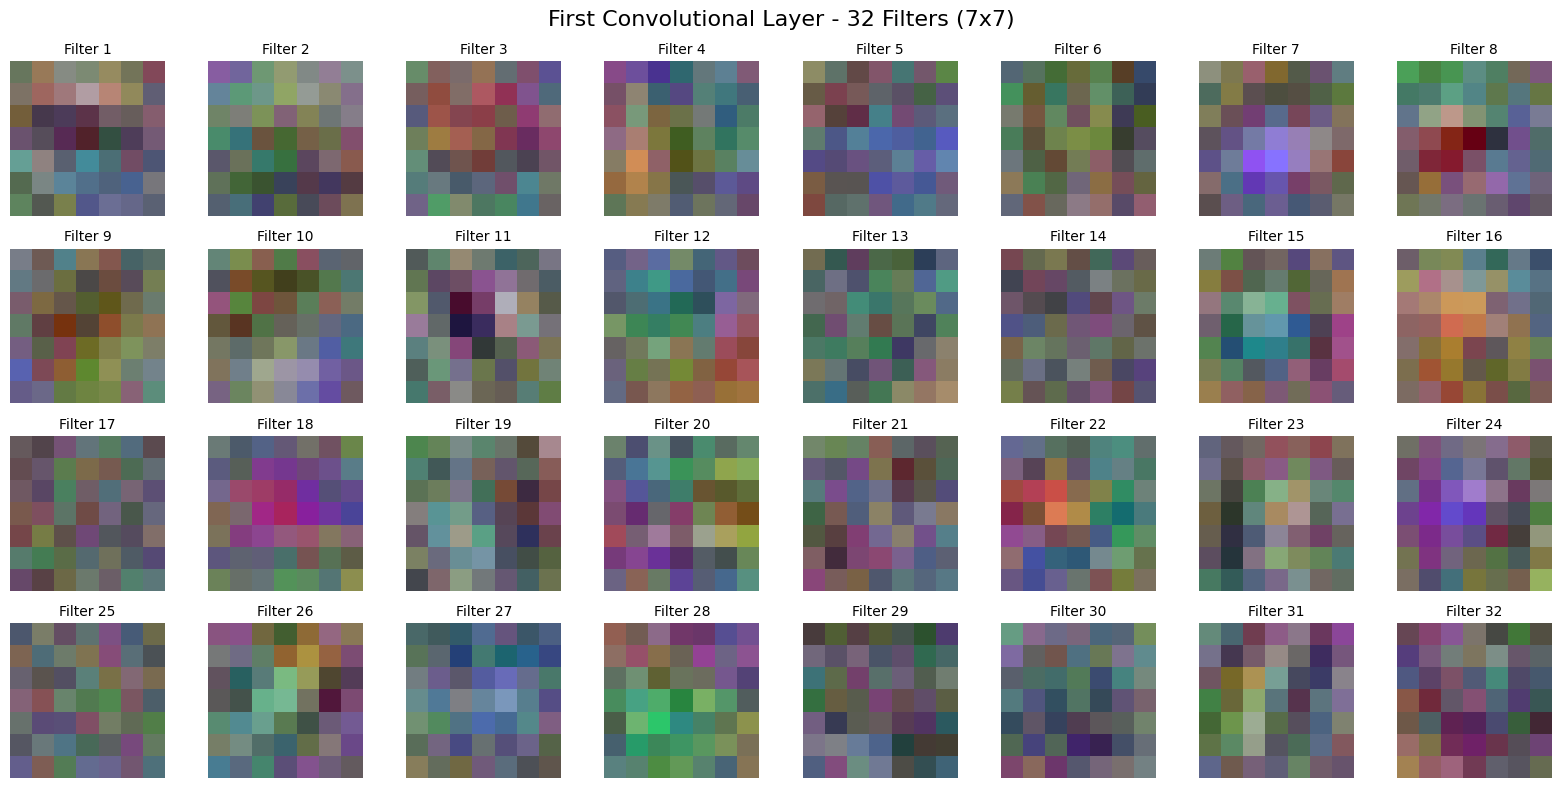

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# Get trained weights of first convolution layer
conv1 = best_model.get_layer("conv1")
filters, biases = conv1.get_weights()

print("Conv1 filter shape:", filters.shape)

# Normalize filters for visualization
f_min = filters.min()
f_max = filters.max()

filters_vis = (filters - f_min) / (f_max - f_min + 1e-8)

# Show 32 filters
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(filters_vis[:, :, :, i])
    ax.set_title(f"Filter {i+1}", fontsize=10)
    ax.axis("off")

plt.suptitle(
    "First Convolutional Layer - 32 Filters (7x7)",
    fontsize=16
)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/conv1_filters_7x7.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Feature maps shape: (1, 32, 32, 32)


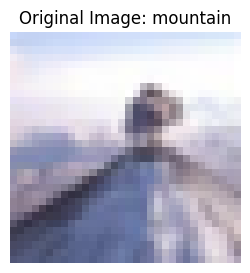

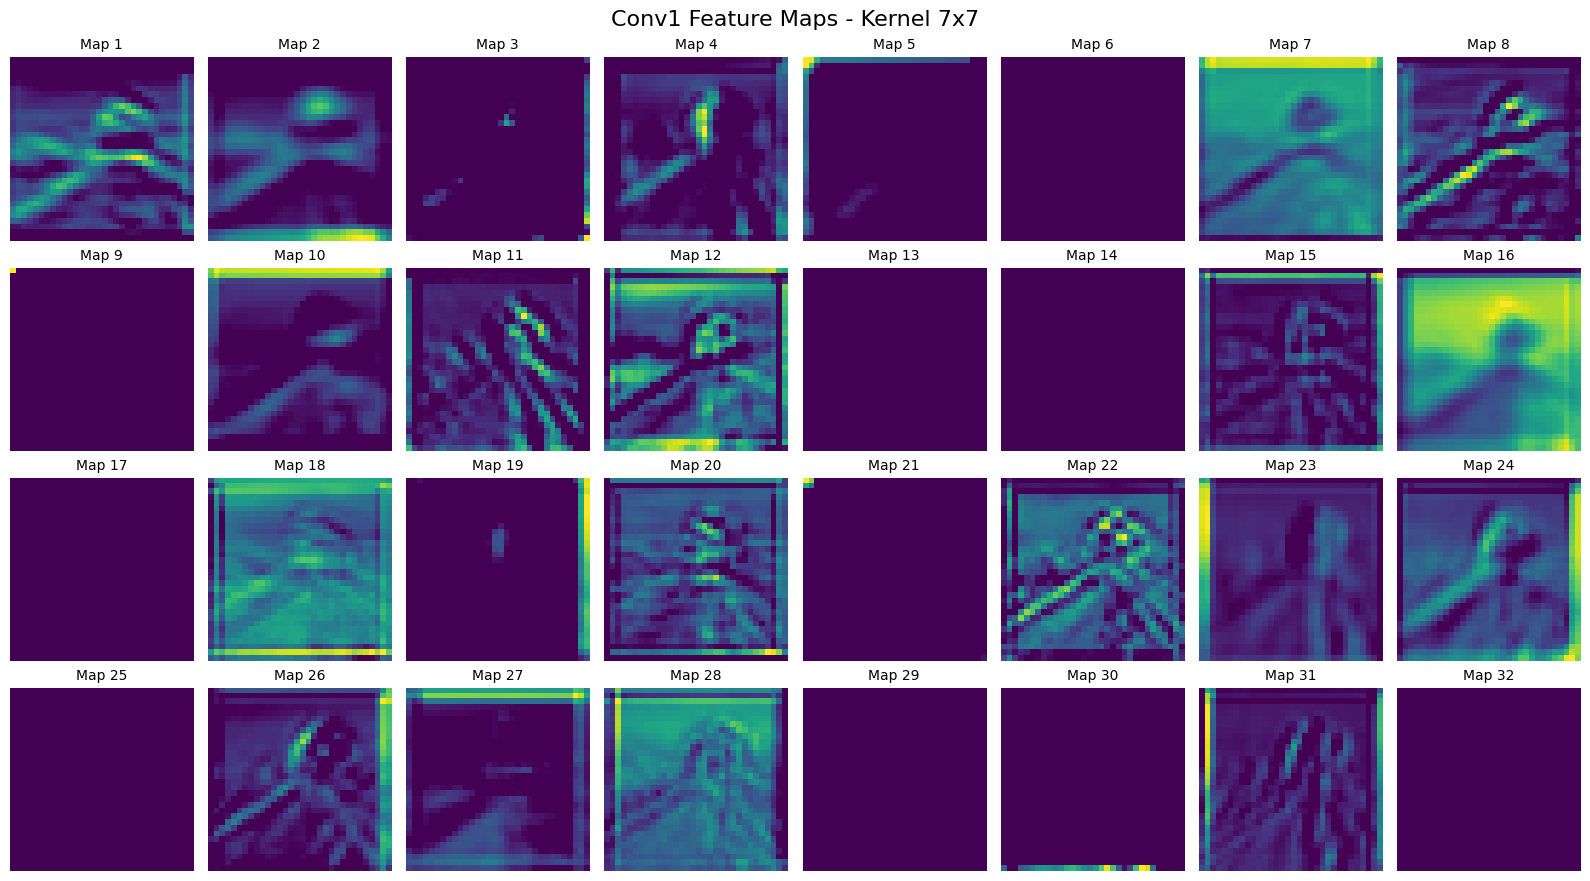

In [16]:

from tensorflow.keras import Model

# Select one test image
image_index = 0
sample_image = X_test[image_index:image_index+1]

# Create a model to extract Conv1 output
feature_model = Model(
    inputs=best_model.inputs,
    outputs=best_model.get_layer("conv1").output
)

# Predict feature maps
feature_maps = feature_model.predict(
    sample_image, verbose=0
)

print("Feature maps shape:", feature_maps.shape)

# Show original image
plt.figure(figsize=(3, 3))
plt.imshow(X_test[image_index])
plt.title(
    f"Original Image: {class_names[Y_test[image_index]]}"
)
plt.axis("off")
plt.show()

# Show 32 activation maps
fig, axes = plt.subplots(4, 8, figsize=(16, 9))

for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Map {i+1}", fontsize=10)
    ax.axis("off")

plt.suptitle(
    "Conv1 Feature Maps - Kernel 7x7",
    fontsize=16
)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/conv1_feature_maps_7x7.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


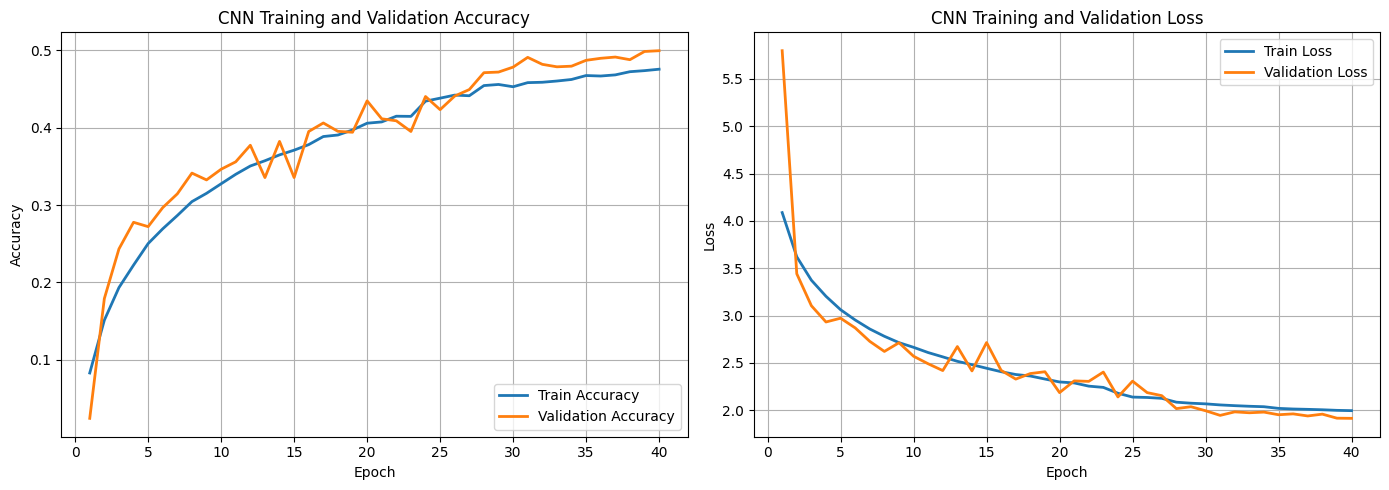

In [17]:

import matplotlib.pyplot as plt
import numpy as np

# Get training history
train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = np.arange(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    epochs, train_acc,
    label="Train Accuracy",
    linewidth=2
)
axes[0].plot(
    epochs, val_acc,
    label="Validation Accuracy",
    linewidth=2
)
axes[0].set_title("CNN Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right")
axes[0].grid(True)

# Loss
axes[1].plot(
    epochs, train_loss,
    label="Train Loss",
    linewidth=2
)
axes[1].plot(
    epochs, val_loss,
    label="Validation Loss",
    linewidth=2
)
axes[1].set_title("CNN Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(loc="upper right")
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/training_accuracy_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [2]:

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

tf.keras.utils.set_random_seed(42)

L2 = regularizers.l2(1e-4)

augmentation_v3 = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomRotation(0.03),
], name="augmentation_v3")

model_v3 = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    augmentation_v3,

    # Block 1 - First Conv 7x7
    layers.Conv2D(
        32, (7, 7), padding="same",
        use_bias=False, name="conv1"
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(
        64, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Block 2
    layers.Conv2D(
        128, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(
        128, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.2),

    # Block 3
    layers.Conv2D(
        256, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(
        256, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.3),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=L2
    ),
    layers.Dropout(0.35),

    layers.Dense(
        100,
        activation="softmax"
    )
])

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v3.summary()


I0000 00:00:1792201769.103587      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792201769.107639      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation_v3 (Sequential)    │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │         4,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 256)      │             

 Total params: 1,224,004 (4.67 MB)

 Trainable params: 1,222,276 (4.66 MB)

 Non-trainable params: 1,728 (6.75 KB)

In [3]:

import numpy as np
import pickle

# Dataset path
DATA_DIR = "/kaggle/input/datasets/fedesoriano/cifar100"

def load_cifar_file(filename):
    with open(f"{DATA_DIR}/{filename}", "rb") as f:
        return pickle.load(f, encoding="bytes")

# Load dataset
train_data = load_cifar_file("train")
test_data = load_cifar_file("test")

x_train = train_data[b"data"].reshape(
    -1, 3, 32, 32
).transpose(0, 2, 3, 1)

y_train = np.array(train_data[b"fine_labels"])

x_test = test_data[b"data"].reshape(
    -1, 3, 32, 32
).transpose(0, 2, 3, 1)

y_test = np.array(test_data[b"fine_labels"])

# Split Train / Validation
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train))

train_idx = indices[:45000]
val_idx = indices[45000:]

X_train = x_train[train_idx].astype("float32") / 255.0
Y_train = y_train[train_idx]

X_val = x_train[val_idx].astype("float32") / 255.0
Y_val = y_train[val_idx]

X_test = x_test.astype("float32") / 255.0
Y_test = y_test

print("DATA READY!")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


DATA READY!
Train: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Test: (10000, 32, 32, 3)


In [4]:

callbacks_v3 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        min_delta=0.001,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_cifar100_cnn_v3.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_v3 = model_v3.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=70,
    batch_size=128,
    callbacks=callbacks_v3,
    verbose=1
)


Epoch 1/70


E0000 00:00:1792201850.395198      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 51ms/step - accuracy: 0.0833 - loss: 4.0902 - val_accuracy: 0.0302 - val_loss: 4.9088 - learning_rate: 3.0000e-04
Epoch 2/70
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.1600 - loss: 3.5302 - val_accuracy: 0.1966 - val_loss: 3.3515 - learning_rate: 3.0000e-04
Epoch 3/70
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.2116 - loss: 3.2168 - val_accuracy: 0.2256 - val_loss: 3.2576 - learning_rate: 3.0000e-04
Epoch 4/70
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.2561 - loss: 2.9878 - val_accuracy: 0.2894 - val_loss: 2.8666 - learning_rate: 3.0000e-04
Epoch 5/70
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.2848 - loss: 2.8212 - val_accuracy: 0.3014 - val_loss: 2.7537 - learning_rate: 3.0000e-04
Epoch 6/70
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.3146 - loss: 2.6864 - val_accuracy: 0.3388 - val_loss: 2.6373 - learning_rate: 3.0000e-04
Epoch 7/70
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 50ms/step - accurac

CNN V2 vs CNN V3


,Model,Best Val Accuracy,Best Val Loss,Epochs
0,CNN V2,0.454,2.1017,40
1,CNN V3,0.609,1.4927,70


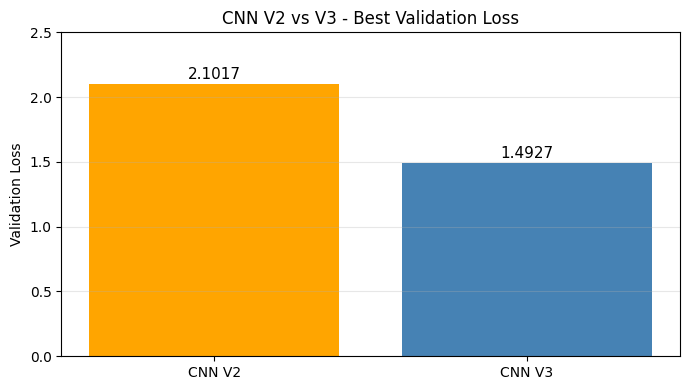

In [5]:

import pandas as pd
import matplotlib.pyplot as plt

# Results from previous Kaggle training logs
results = pd.DataFrame({
    "Model": ["CNN V2", "CNN V3"],
    "Best Val Accuracy": [0.4540, 0.6090],
    "Best Val Loss": [2.1017, 1.4927],
    "Epochs": [40, 70]
})

print("CNN V2 vs CNN V3")
display(results)

# Compare validation loss
plt.figure(figsize=(7, 4))

plt.bar(
    results["Model"],
    results["Best Val Loss"],
    color=["orange", "steelblue"]
)

plt.title("CNN V2 vs V3 - Best Validation Loss")
plt.ylabel("Validation Loss")
plt.ylim(0, 2.5)

for i, value in enumerate(results["Best Val Loss"]):
    plt.text(
        i, value + 0.04,
        f"{value:.4f}",
        ha="center",
        fontsize=11
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/v2_vs_v3_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [6]:

import os

model_path = "/kaggle/working/best_cifar100_cnn_v3.keras"

if os.path.exists(model_path):
    print("CNN V3 model found!")
    print("Path:", model_path)
else:
    print("CNN V3 model NOT found!")


CNN V3 model found!
Path: /kaggle/working/best_cifar100_cnn_v3.keras


In [8]:

import os

print("SEARCHING SAVED CNN MODELS...")
print("=" * 50)

found = []

for root_dir in ["/kaggle/working", "/kaggle/input"]:
    for root, dirs, files in os.walk(root_dir):
        for file in files:
            if file.endswith((".keras", ".h5", ".hdf5")):
                path = os.path.join(root, file)
                found.append(path)
                print("FOUND:", path)

if not found:
    print("No saved model files found.")

print("=" * 50)


SEARCHING SAVED CNN MODELS...
FOUND: /kaggle/working/best_cifar100_cnn_v3.keras


In [9]:

# Check models in current Kaggle session

print("model_v3 exists:", "model_v3" in globals())
print("best_model_v3 exists:", "best_model_v3" in globals())
print("history_v3 exists:", "history_v3" in globals())


model_v3 exists: True
best_model_v3 exists: False
history_v3 exists: True


In [10]:

import os
import pandas as pd

SAVE_DIR = "/kaggle/working"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save model currently in memory
model_v3.save(
    f"{SAVE_DIR}/cnn_v3_recovered.keras"
)

# Save 70-epoch training history
history_df = pd.DataFrame(history_v3.history)

history_df.to_csv(
    f"{SAVE_DIR}/cnn_v3_history.csv",
    index=False
)

# Identify best epoch by validation loss
best_epoch = history_df["val_loss"].idxmin() + 1

print("MODEL SAVED SUCCESSFULLY!")
print("Model: cnn_v3_recovered.keras")
print("History: cnn_v3_history.csv")
print("Best Epoch:", best_epoch)
print(
    "Best Validation Loss:",
    history_df["val_loss"].min()
)
print(
    "Best Validation Accuracy:",
    history_df["val_accuracy"].max()
)


MODEL SAVED SUCCESSFULLY!
Model: cnn_v3_recovered.keras
History: cnn_v3_history.csv
Best Epoch: 69
Best Validation Loss: 1.4779043197631836
Best Validation Accuracy: 0.6055999994277954


In [11]:

import tensorflow as tf

# Load recovered CNN V3
best_model_v3 = tf.keras.models.load_model(
    "/kaggle/working/cnn_v3_recovered.keras"
)

# Evaluate on test data
test_loss_v3, test_acc_v3 = best_model_v3.evaluate(
    X_test,
    Y_test,
    batch_size=128,
    verbose=1
)

print("=" * 45)
print("CNN V3 - CIFAR-100 TEST RESULTS")
print("=" * 45)
print(f"Test Accuracy: {test_acc_v3 * 100:.2f}%")
print(f"Test Loss    : {test_loss_v3:.4f}")


79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5918 - loss: 1.5428
CNN V3 - CIFAR-100 TEST RESULTS
Test Accuracy: 59.18%
Test Loss    : 1.5428


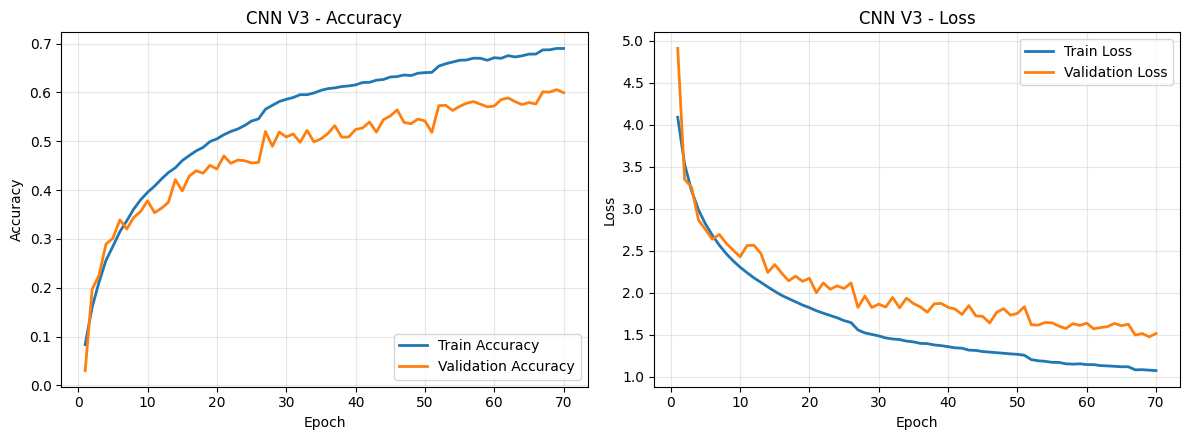

In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load V3 training history
df = pd.read_csv(
    "/kaggle/working/cnn_v3_history.csv"
)

epochs = np.arange(1, len(df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Accuracy
axes[0].plot(
    epochs, df["accuracy"],
    label="Train Accuracy", linewidth=2
)
axes[0].plot(
    epochs, df["val_accuracy"],
    label="Validation Accuracy", linewidth=2
)
axes[0].set_title("CNN V3 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(
    epochs, df["loss"],
    label="Train Loss", linewidth=2
)
axes[1].plot(
    epochs, df["val_loss"],
    label="Validation Loss", linewidth=2
)
axes[1].set_title("CNN V3 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/kaggle/working/cnn_v3_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Conv1 filter shape: (7, 7, 3, 32)


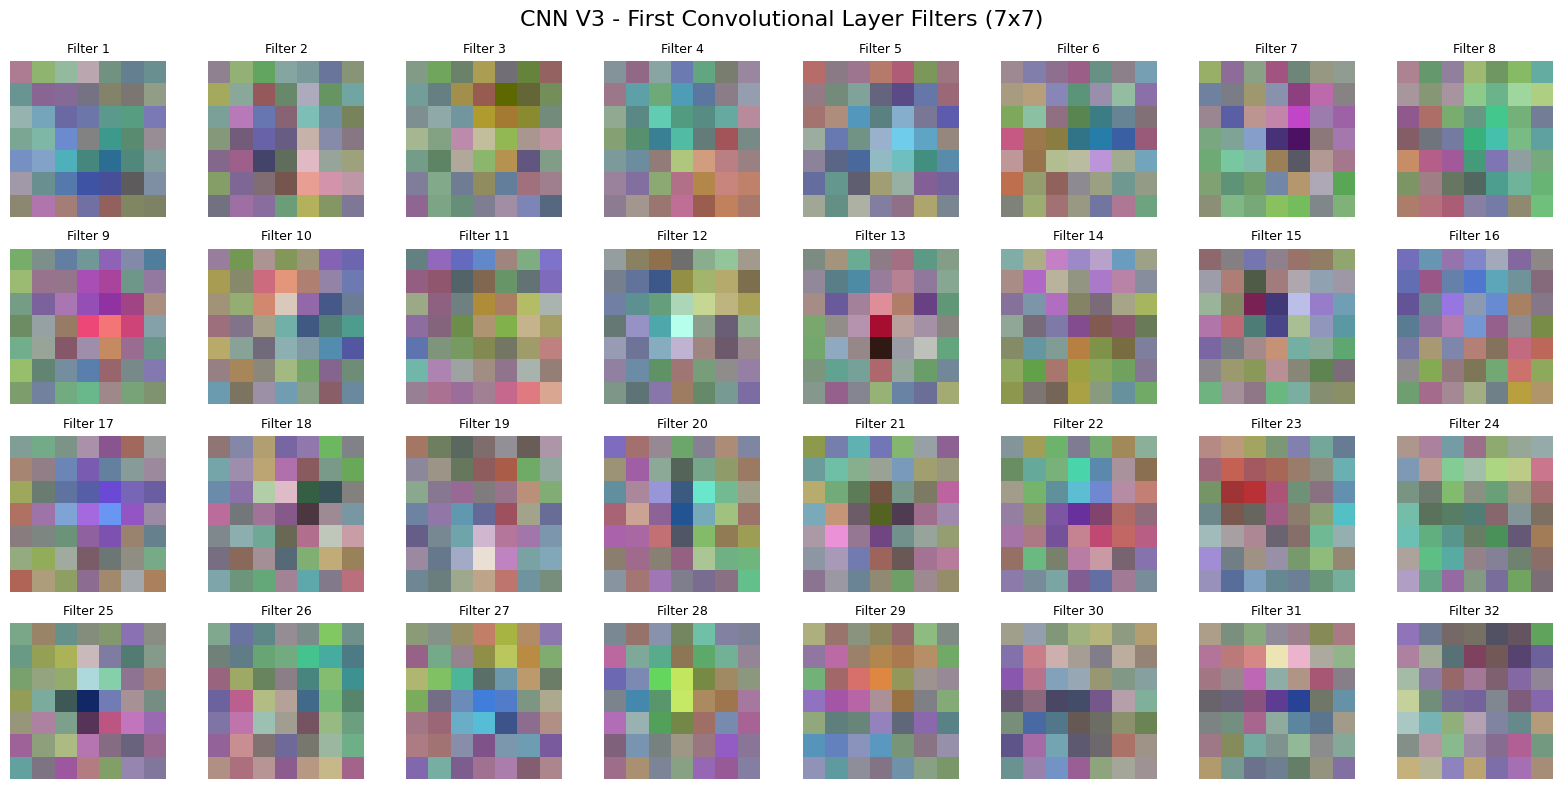

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load V3 model if needed
best_model_v3 = tf.keras.models.load_model(
    "/kaggle/working/cnn_v3_recovered.keras"
)

# Get conv1 weights
conv1 = best_model_v3.get_layer("conv1")
filters = conv1.get_weights()[0]   # shape: (7, 7, 3, 32)

print("Conv1 filter shape:", filters.shape)

# Normalize filters for visualization
f_min, f_max = filters.min(), filters.max()
filters_vis = (filters - f_min) / (f_max - f_min + 1e-8)

# Plot 32 filters
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(filters_vis[:, :, :, i])
    ax.set_title(f"Filter {i+1}", fontsize=9)
    ax.axis("off")

plt.suptitle("CNN V3 - First Convolutional Layer Filters (7x7)", fontsize=16)
plt.tight_layout()
plt.savefig("/kaggle/working/cnn_v3_conv1_filters.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:

import pickle
import os

# CIFAR-100 metadata path
meta_path = "/kaggle/input/datasets/fedesoriano/cifar100/meta"

# Load 100 class names
with open(meta_path, "rb") as f:
    meta_data = pickle.load(f, encoding="bytes")

class_names = [
    name.decode("utf-8")
    for name in meta_data[b"fine_label_names"]
]

print("Number of classes:", len(class_names))
print("First 10 classes:", class_names[:10])


Number of classes: 100
First 10 classes: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']


Conv1 kernel: (7, 7)
Feature Maps shape: (1, 32, 32, 32)


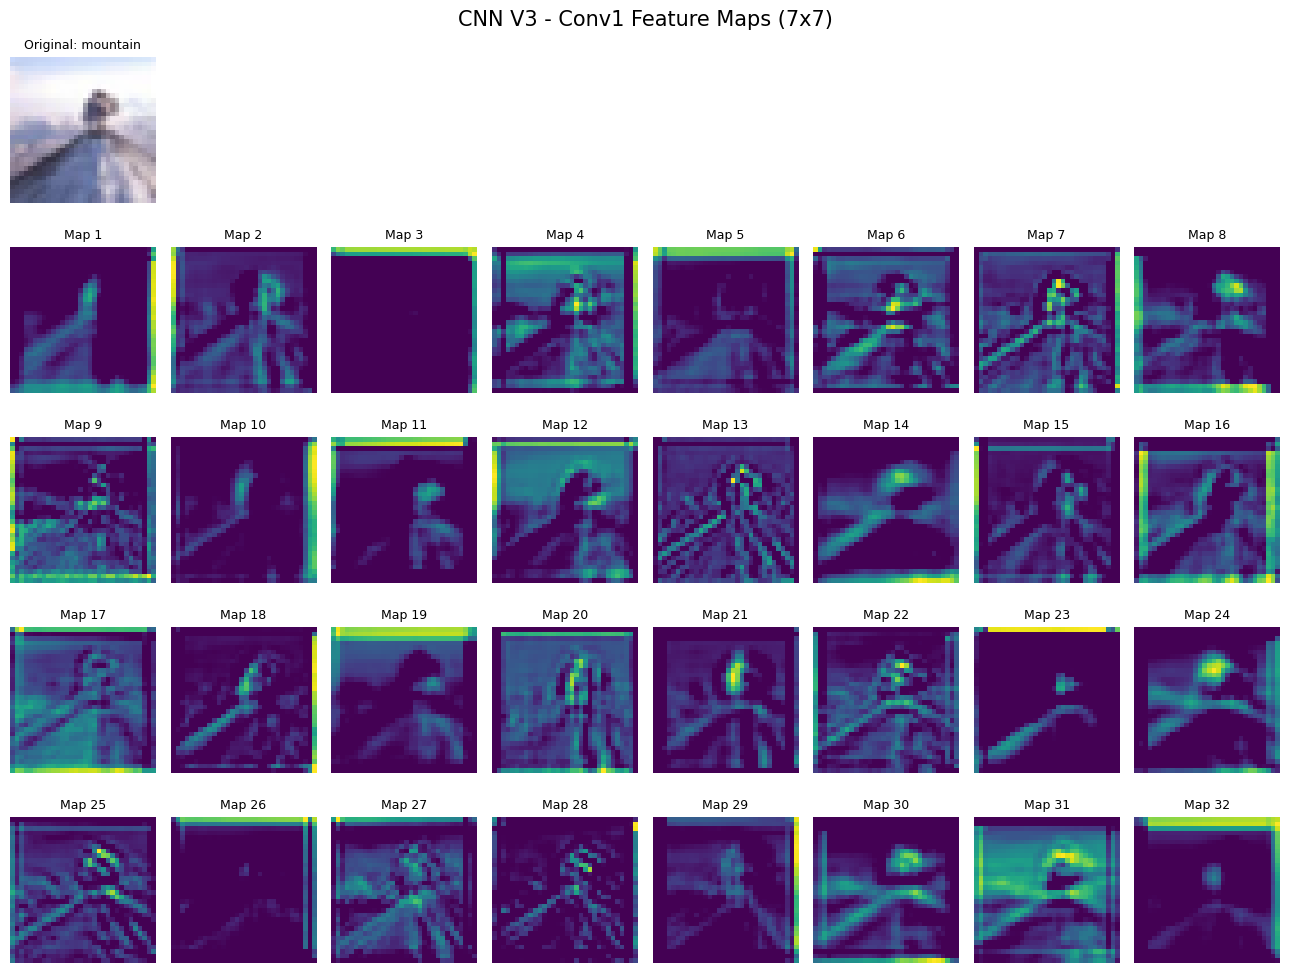

In [15]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load saved CNN V3 if needed
if "best_model_v3" not in globals():
    best_model_v3 = tf.keras.models.load_model(
        "/kaggle/working/cnn_v3_recovered.keras"
    )

# Select one test image
image_index = 0
sample_image = X_test[image_index:image_index + 1]

# Find Conv1 and first ReLU after Conv1
layers_list = best_model_v3.layers

conv1_idx = next(
    i for i, layer in enumerate(layers_list)
    if layer.name == "conv1"
)

relu_idx = next(
    i for i in range(conv1_idx + 1, len(layers_list))
    if isinstance(layers_list[i], tf.keras.layers.Activation)
    and layers_list[i].activation.__name__ == "relu"
)

# Execute layers from input to first ReLU
# This avoids the Sequential .input error
x = tf.convert_to_tensor(sample_image)

for layer in layers_list[:relu_idx + 1]:
    x = layer(x, training=False)

feature_maps = x.numpy()

print("Conv1 kernel:", 
      best_model_v3.get_layer("conv1").kernel_size)
print("Feature Maps shape:", feature_maps.shape)

# Plot original image + feature maps
fig = plt.figure(figsize=(13, 10))

ax = fig.add_subplot(5, 8, 1)
ax.imshow(X_test[image_index])
ax.set_title(
    f"Original: {class_names[int(Y_test[image_index])]}",
    fontsize=9
)
ax.axis("off")

for i in range(32):
    ax = fig.add_subplot(5, 8, i + 9)
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Map {i+1}", fontsize=9)
    ax.axis("off")

plt.suptitle(
    "CNN V3 - Conv1 Feature Maps (7x7)",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/cnn_v3_feature_maps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


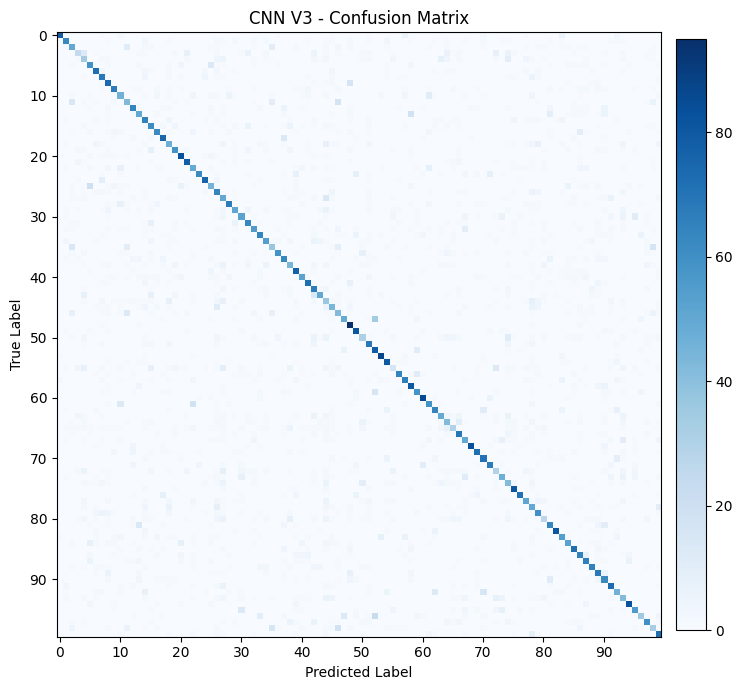

CNN V3 - Classification Report


,precision,recall,f1-score,support
apple,0.9512,0.7800,0.8571,100.0000
aquarium_fish,0.7326,0.6300,0.6774,100.0000
baby,0.4673,0.5000,0.4831,100.0000
bear,0.5333,0.2400,0.3310,100.0000
beaver,0.3208,0.3400,0.3301,100.0000
...,...,...,...,...
woman,0.4648,0.3300,0.3860,100.0000
worm,0.6000,0.7200,0.6545,100.0000
accuracy,0.5918,0.5918,0.5918,0.5918
macro avg,0.6033,0.5918,0.5905,10000.0000


TOP 10 CLASSES - HIGHEST F1


,precision,recall,f1-score,support
road,0.9432,0.83,0.8830,100.0
sunflower,0.9310,0.81,0.8663,100.0
apple,0.9512,0.78,0.8571,100.0
orange,0.8447,0.87,0.8571,100.0
wardrobe,0.8646,0.83,0.8469,100.0
plain,0.7727,0.85,0.8095,100.0
cockroach,0.8261,0.76,0.7917,100.0
skyscraper,0.8765,0.71,0.7845,100.0
chair,0.7217,0.83,0.7721,100.0
chimpanzee,0.7429,0.78,0.7610,100.0


BOTTOM 10 CLASSES - LOWEST F1


,precision,recall,f1-score,support
otter,0.3019,0.16,0.2092,100.0
lizard,0.2368,0.36,0.2857,100.0
beaver,0.3208,0.34,0.3301,100.0
bear,0.5333,0.24,0.3310,100.0
seal,0.3846,0.30,0.3371,100.0
squirrel,0.4655,0.27,0.3418,100.0
mouse,0.4493,0.31,0.3669,100.0
rabbit,0.4762,0.30,0.3681,100.0
turtle,0.3415,0.42,0.3767,100.0
shrew,0.3529,0.42,0.3836,100.0


In [16]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Predict using CNN V3
y_prob_v3 = best_model_v3.predict(
    X_test, batch_size=128, verbose=1
)

y_pred_v3 = np.argmax(y_prob_v3, axis=1)

# Confusion Matrix
cm_v3 = confusion_matrix(
    Y_test, y_pred_v3,
    labels=np.arange(100)
)

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    cm_v3, cmap="Blues",
    interpolation="nearest"
)

ticks = np.arange(0, 100, 10)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

ax.set_title("CNN V3 - Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/cnn_v3_confusion_matrix.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Classification Report
report_v3 = classification_report(
    Y_test, y_pred_v3,
    labels=np.arange(100),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df_v3 = pd.DataFrame(report_v3).transpose()

report_df_v3.to_csv(
    "/kaggle/working/cnn_v3_classification_report.csv"
)

print("CNN V3 - Classification Report")
display(report_df_v3.round(4))

# Top and Bottom 10 classes
class_df_v3 = report_df_v3.loc[class_names]

print("TOP 10 CLASSES - HIGHEST F1")
display(
    class_df_v3.nlargest(10, "f1-score").round(4)
)

print("BOTTOM 10 CLASSES - LOWEST F1")
display(
    class_df_v3.nsmallest(10, "f1-score").round(4)
)


In [17]:

import os

files = [
    "/kaggle/working/cnn_v3_recovered.keras",
    "/kaggle/working/cnn_v3_history.csv"
]

for path in files:
    if os.path.isfile(path):
        print("FOUND:", path)
        print("Size:", round(os.path.getsize(path)/1024/1024, 2), "MB")
    else:
        print("NOT FOUND:", path)

print("\nModel in memory:", "model_v3" in globals())
print("History in memory:", "history_v3" in globals())


FOUND: /kaggle/working/cnn_v3_recovered.keras
Size: 14.11 MB
FOUND: /kaggle/working/cnn_v3_history.csv
Size: 0.01 MB

Model in memory: True
History in memory: True


In [18]:

import os
import zipfile

SOURCE_DIR = "/kaggle/working"
ZIP_PATH = "/kaggle/working/CNN_CIFAR100_V3_Backup.zip"

# Compress all files in /kaggle/working
with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(SOURCE_DIR):
        for filename in files:
            file_path = os.path.join(root, filename)

            # Avoid including ZIP inside itself
            if os.path.abspath(file_path) == os.path.abspath(ZIP_PATH):
                continue

            relative_path = os.path.relpath(
                file_path, SOURCE_DIR
            )

            zipf.write(
                file_path,
                arcname=relative_path
            )

print("ZIP CREATED SUCCESSFULLY!")
print("Path:", ZIP_PATH)
print(
    "Size:",
    round(os.path.getsize(ZIP_PATH) / 1024**2, 2),
    "MB"
)

# Verify ZIP integrity
with zipfile.ZipFile(ZIP_PATH, "r") as zipf:
    print("Files inside ZIP:", len(zipf.namelist()))
    print("Integrity check:", zipf.testzip())


ZIP CREATED SUCCESSFULLY!
Path: /kaggle/working/CNN_CIFAR100_V3_Backup.zip
Size: 26.13 MB
Files inside ZIP: 10
Integrity check: None


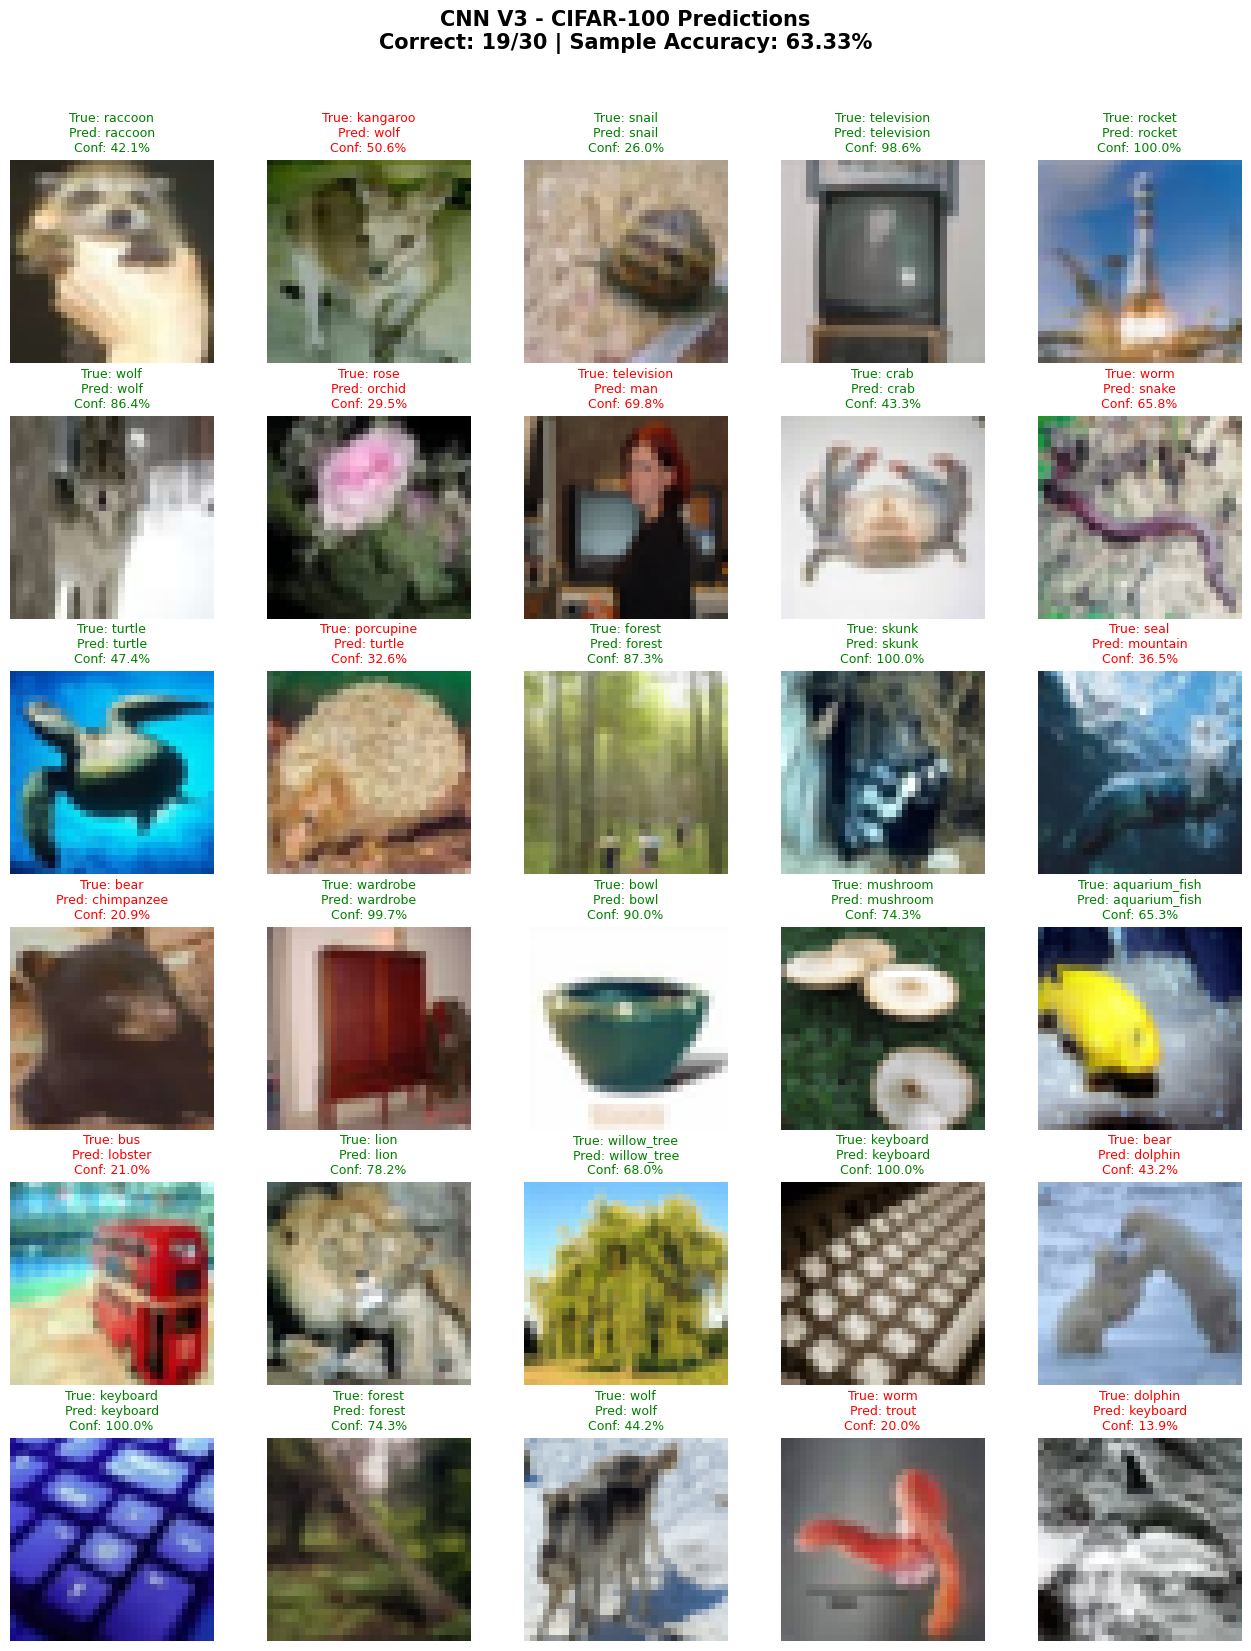

CNN V3 - MULTIPLE IMAGE TEST
Number of images : 30
Correct          : 19
Incorrect        : 11
Sample Accuracy  : 63.33%


In [20]:

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ========================================
# 1. CONFIGURATION
# ========================================

NUM_IMAGES = 30       # Number of test images
NUM_COLUMNS = 5        # Images per row
RANDOM_SEED = 42

MODEL_PATH = "/kaggle/working/best_cifar100_cnn_v3.keras"

if not os.path.exists(MODEL_PATH):
    MODEL_PATH = "/kaggle/working/cnn_v3_recovered.keras"

# ========================================
# 2. LOAD TRAINED MODEL
# ========================================

best_model_v3 = tf.keras.models.load_model(MODEL_PATH)

# ========================================
# 3. SELECT RANDOM TEST IMAGES
# ========================================

rng = np.random.default_rng(RANDOM_SEED)

indices = rng.choice(
    len(X_test),
    size=NUM_IMAGES,
    replace=False
)

images = X_test[indices]
true_labels = np.asarray(Y_test).reshape(-1)[indices]

# ========================================
# 4. PREDICT
# ========================================

predictions = best_model_v3.predict(
    images,
    batch_size=128,
    verbose=0
)

predicted_labels = np.argmax(predictions, axis=1)

confidence_scores = np.max(predictions, axis=1)

correct = predicted_labels == true_labels

sample_accuracy = np.mean(correct) * 100

# ========================================
# 5. VISUALIZE RESULTS
# ========================================

num_rows = int(np.ceil(NUM_IMAGES / NUM_COLUMNS))

fig, axes = plt.subplots(
    num_rows,
    NUM_COLUMNS,
    figsize=(NUM_COLUMNS * 2.6, num_rows * 2.8),
    squeeze=False
)

for i, ax in enumerate(axes.flat):

    if i >= NUM_IMAGES:
        ax.axis("off")
        continue

    ax.imshow(images[i])

    true_name = class_names[int(true_labels[i])]
    pred_name = class_names[int(predicted_labels[i])]

    color = "green" if correct[i] else "red"

    ax.set_title(
        f"True: {true_name}\n"
        f"Pred: {pred_name}\n"
        f"Conf: {confidence_scores[i]:.1%}",
        fontsize=9,
        color=color
    )

    ax.axis("off")

plt.suptitle(
    f"CNN V3 - CIFAR-100 Predictions\n"
    f"Correct: {np.sum(correct)}/{NUM_IMAGES} | "
    f"Sample Accuracy: {sample_accuracy:.2f}%",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "/kaggle/working/cnn_v3_multiple_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ========================================
# 6. SUMMARY
# ========================================

print("=" * 45)
print("CNN V3 - MULTIPLE IMAGE TEST")
print("=" * 45)
print(f"Number of images : {NUM_IMAGES}")
print(f"Correct          : {np.sum(correct)}")
print(f"Incorrect        : {np.sum(~correct)}")
print(f"Sample Accuracy  : {sample_accuracy:.2f}%")
print("=" * 45)
